Algoritmos Genéticos y Optimización Heurística - UTN-FRT
# **Trabajo Práctico N°4**
##**Tema**: Algoritmo Genético Simple##

## Ejercicio 1
Complete los fragmentos faltantes del código de los operadores genéticos que se muestran a continuación (reutilice el código del Trabajo Práctico anterior). Pruebe el Algoritmo Genético con la función F(x, y) = floor(x) + floor(y), x,y ∈ [-5.12, 5.12].

In [6]:
import random, math

# Verificación de la entrada
def verification_process(cant_soluc, Bounds, cant_variables, Enteras, cant_cruzados, cant_mutados, cant_elite):
    tieneErrores = False
    if cant_soluc < 2:
        print('La población debe tener al menos dos individuos.')
        tieneErrores = True
    if len(Bounds) != cant_variables or len(Bounds[0]) != 2:
        print('El tamaño de la matriz Bounds es incorrecto.')
        tieneErrores = True
    if len(Enteras) != cant_variables:
        print('El tamaño del vector Enteras es incorrecto.')
        tieneErrores = True
    if cant_cruzados > cant_soluc:
        print('La cantidad de cruzados debe ser menor o igual que el tamaño de la población.')
        tieneErrores = True
    if cant_mutados > cant_soluc:
        print('La cantidad de mutados debe ser menor o igual que el tamaño de la población.')
        tieneErrores = True
    if cant_elite >= cant_soluc:
        print('El tamaño de la élite debe ser menor que el tamaño de la población.')
        tieneErrores = True
    return tieneErrores


def geneticoSimple(Pop, cant_generac, Bounds, Enteras, sel, xover, mut, \
                   cant_cruzados, cant_mutados, cant_elite, param_sel, f, callback=None):
    """
    Algoritmo Genetico Simple
    Parametros:
    - Pop: list. poblacion inicial (lista de listas).
    - cant_generac: int. Cantidad de iteraciones del algoritmo.
    - Bounds: list: Matriz que indica los valores max y min de cada variable.
    - Enteras: list. Vector booleano que indica si las coordenadas son enteras.
    - cant_cruzados: int. Cantidad de individuos que seran cruzados.
    - cant_mutados: int. Cantidad de soluciones a las cuales se le aplicara
      mutacion.
    - cant_elite: int. Numero de mejores soluciones que pasan a la siguiente
      generacion sin cambio alguno.
    - param_sel: float. Parametro usado en la seleccion, por ejemplo el peso que
      se le asigna a la solucion menos probable en el calculo de la probabilidad
      para ruleta. En caso de usar torneo, este es el tamano del torneo.
    - f: function. Funcion de evaluacion. Debe recibir como parametro un vector
      solucion y devolver un numero real.
    - callback: function. Funcion que se ejecuta una vez en cada iteracion (para
      mostrar resultados parciales). Usar None para deshabilitarla.
    Salida
    - soluc: list. Vector solucion que obtuvo fitness mas alto.
    - solF: float. Valor de evaluacion de la mejor solucion.
    - Pop: list. Poblacion final.
    - Fit: list. Fitness de cada individuo de la poblacion final.
    - traceBest: list. Vector con los mejores valores de fitness obtenidos en
      cada generacion. Se puede utilizar para determinar si el algoritmo
      llego a crowding.
    - traceAvg: list. Vector con los valores promedio de fitness
      obtenidos en cada generacion.
    """
    # Inicializacion sobre los parámetros de la solución
    sol = []
    solF = None
    cant_soluc = len(Pop)
    Fit = [None] * cant_soluc
    traceBest = []
    traceAvg = []
    bestSols = []

    tieneErrores = verification_process(cant_soluc, Bounds, len(Pop[0]), Enteras, cant_cruzados, cant_mutados, cant_elite)

    if tieneErrores:
        return sol, solF, Pop, Fit, traceBest, traceAvg, bestSols

    #inicializo variables para reducir tiempo de calculo
    cb_param = None
    p = [i for i in range(cant_soluc)]

    #realizo las evaluaciones de la poblacion inicial.
    for k in range(cant_soluc):
        Pop[k] = [xi if not Enteras[i] else int(xi+0.5) for i, xi in enumerate(Pop[k])]
        Fit[k] = f(Pop[k])
    if callback != None:
        cb_param = callback(Pop, Fit, Bounds, 0, cant_generac, cb_param)
    #obtengo el orden de los individuos
    p_orden = sorted(range(len(Fit)), key=lambda k: Fit[k], reverse=True)

    for gen in range(cant_generac):
        #selecciono la elite de la generacion actual (una copia)
        Elite = [[xi for xi in Pop[p_orden[k]]] for k in range(cant_elite)]
        Elite_Fit = [Fit[p_orden[k]] for k in range(cant_elite)]

        #seleccion
        p_sel = sel(Fit, cant_soluc, param_sel)
        random.shuffle(p)
        Pop = [Pop[p_sel[k]] for k in p]
        Fit = [Fit[p_sel[k]] for k in p]

        #cruzamiento
        random.shuffle(p)
        for k in range(0, cant_cruzados-1, 2):
            C1, C2 = xover(Pop[p[k]], Pop[p[k+1]])
            Pop[p[k]] = [xi for xi in C1]
            Pop[p[k+1]] = [xi for xi in C2]
            Fit[p[k]] = None
            Fit[p[k+1]] = None

        #mutacion
        random.shuffle(p)
        for k in range(cant_mutados):
            C = mut(Pop[p[k]], Bounds)
            Pop[p[k]] = [xi for xi in C]
            Fit[p[k]] = None

        #inserto la elite en la nueva poblacion en lugares al azar
        random.shuffle(p)
        for k in range(cant_elite):
            Pop[p[k]] = Elite[k]
            Fit[p[k]] = Elite_Fit[k]

        #realizo las evaluaciones de la nueva generacion
        for k in range(cant_soluc):
            if Fit[k] == None:
                Pop[k] = [xi if not Enteras[i] else int(xi+0.5) for i, xi in enumerate(Pop[k])]
                Fit[k] = f(Pop[k]);

        #obtengo el orden de los individuos
        p_orden = sorted(range(len(Fit)), key=lambda k: Fit[k], reverse=True)

        #datos estadisticos
        traceBest.append(Fit[p_orden[0]])
        traceAvg.append(sum(Fit) / len(Fit))
        bestSols.append([xi for xi in Pop[p_orden[0]]])

        #funcion para graficar, mostrar, etc.
        if callback != None:
            cb_param = callback(Pop, Fit, Bounds, gen, cant_generac, cb_param)

    #busco la mejor solucion obtenida
    solF = Fit[p_orden[0]]
    sol = Pop[p_orden[0]]

    return sol, solF, Pop, Fit, traceBest, traceAvg, bestSols

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.ticker import LinearLocator, FormatStrFormatter
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import clear_output
from time import sleep

def graficarEvolucionFitness(best, mean):
    """Método para graficar la evolucion del fitness con las iteraciones.
    Parametros
    best, mean : list. Lista con los valores de evaluación de la mejor y peor solución.
    """
    fig = plt.figure()
    ax = plt.axes()
    x = range(len(best));
    plt.plot(x, best, label='Mejor solución');
    plt.plot(x, mean, label='Promedio poblacion');
    plt.title('Valores de Evaluación')
    plt.xlabel('Iteración')
    plt.ylabel('Fitness')
    plt.grid()
    plt.legend()

def graficarCaminata(fitness, solutions,  bounds, resolution, alpha=0.5):
    """Graficar la funcion de evaluacion y las soluciones encontradas.
    Parametros
    fitness : function. Función de evaluación a optimizar
    solutions : list. Lista de soluciones encontradas.
    bounds: list(tuple). Matriz de tamano nx2, donde n es la cantidad de
    variables del problema (cantidad de coordenadas del vector solución).
    resolution : float. Resolución para graficar la función (mayor a 0.1).
    alpha : float. Transparencia para el grafico de la función.
    """
    ranges = []
    for i in range(len(bounds)):
        steps = round((bounds[i][1] - bounds[i][0]) / resolution)
        ranges.append([bounds[i][0] + s*resolution for s in range(steps)])
    if len(bounds) == 1:
        fig = plt.figure()
        ax = fig.gca()
        X = [xi for xi in ranges[0]]
        Y = [fitness(xi) for xi in ranges[0]]
        plt.plot(X, Y, antialiased=False, alpha=alpha)
        plt.title('Función de Evaluación')
        plt.xlabel('x')
        plt.ylabel('f(x)')
        plt.grid()
        x = [s[0] for s in solutions]
        y = [fitness(s) for s in solutions]
        ax.scatter(x, y, c='k', marker='o')
    elif len(bounds) == 2:
        fig = plt.figure()
        ax = fig.add_subplot(projection='3d')
        X = []; Y = []; Z = []
        for i, xi in enumerate(ranges[0]):
            X.append([xi for yj in ranges[1]])
            Y.append([yj for yj in ranges[1]])
            Z.append([fitness([xi, yj]) for yj in ranges[1]])
        surf = ax.plot_surface(X, Y, np.array(Z), cmap=cm.coolwarm, linewidth=0,
            antialiased=False, alpha=alpha)
        plt.title('Función de Evaluación')
        plt.xlabel('x')
        plt.ylabel('y')
        ax.set_zlabel('f(x,y)')
        fig.colorbar(surf, shrink=0.5, aspect=5)
        x = [s[0] for s in solutions]
        y = [s[1] for s in solutions]
        z = [fitness(s) for s in solutions]
        ax.scatter(x, y, z, c='k', marker='o')
    else:
        return False
    return True

def callback_print(Pop, Fit, Bounds, gen, cant_generac, params):
    """Mostrar el valor de fitness si se encuentra una mejor solucion en la
    generacion actual"""
    v = max(Fit)
    if gen == 0:
        params = v
    if v >= params:
        p = Fit.index(v)
        print("Gen.{0}: {1} ({2})".format(gen, Pop[p], v))
    return params

def callback_graficar(Pop, Fit, Bounds, gen, cant_generac, params):
    v = max(Fit)
    if gen == 0 and len(Bounds) == 2:
        params = v
        plt.figure()
    if v >= params and len(Bounds) == 2:
        fig = plt.gcf()
        ax = fig.gca()
        ax.clear()
        x = [s[0] for s in Pop]
        y = [s[1] for s in Pop]
        ax.scatter(x, y, c='k', marker='o')
        ax.set_xlim(Bounds[0])
        ax.set_ylim(Bounds[1])
        plt.title("Generacion: {0} - Fitness: {1}".format(gen, v))
        plt.xlabel('x')
        plt.ylabel('y')
        plt.grid()
        clear_output(wait=True)
        plt.show()
        sleep(0.1)
    return params

def init_pop(cant_individuos, Bounds):
    return [[random.uniform(B[0],B[1]) for B in Bounds] for i in range(cant_individuos)]

def sel_torneo_con_rep(F, cant_selectos, tam_torneo=2):
    """ Operador de selección por torneos.
    Parametros:
    F: list. Lista de valores de fitness de cada individuo de la población.
    cant_selectos: int. Cantidad de individuos a seleccionar.
    tam_torneo: int. Tamaño del torneo.
    S: list. Lista con las posiciones de los individuos seleccionados.
    """

    S = []
    n = len(F)

    for _ in range(cant_selectos):
        # Elegimos 'tam_torneo' posiciones al azar de la población
        # Recordar que .
        competidores = random.sample(range(n), k=tam_torneo)

        # Gana el competidor que tenga el mayor valor en F
        ganador = max(competidores, key=lambda idx: F[idx])
        S.append(ganador)

    return S

def sel_sus(F, cant_selectos, eps=0.2):
    """ Operador de selección por Muestreo Estocástico Universal (SUS) - Con Reposición.
    Parámetros:
    F: list - Lista de valores de fitness de cada individuo.
    cant_selectos: int - Cantidad de individuos a seleccionar (punteros).
    eps: float - Valor de fitness normalizado para el peor individuo (> 0).
    Retorna:
    S: list - Lista con las POSICIONES de los individuos seleccionados.
    """
    # 1) Normalizar el fitness sin alterar el orden original de F
    min_f = min(F)
    f_norm = [fi - min_f + eps for fi in F]

    # 2) Probabilidad proporcional al fitness normalizado
    total = sum(f_norm)
    probs = [fi / total for fi in f_norm]

    # 3) Probabilidades acumuladas
    cum_probs = []
    suma = 0.0
    for p in probs:
        suma += p
        cum_probs.append(suma)

    # 4) Generar un único punto de arranque en [0, 1/cant_selectos) y avanzar de a pasos constantes
    paso = 1.0 / cant_selectos
    inicio = random.uniform(0, paso)
    punteros = [inicio + i * paso for i in range(cant_selectos)]

    S = []
    idx = 0
    # Recorrido lineal O(N): como los punteros están ordenados, no hace falta reiniciar idx
    for p in punteros:
        while cum_probs[idx] < p:
            idx += 1
        S.append(idx)

    return S

def xov_uniform(P1, P2):
    """Operador Uniform Crossover para Algoritmos Geneticos.
    Parametros:
    P1: list. Lista correspondiente a uno de los individuos padres a cruzar.
    P2: list. Lista correspondiente a uno de los individuos padres a cruzar.
    """

    C1, C2 = [], []
    # Para cada gen se tira una moneda: con prob. 0.5 los hijos lo heredan
    # tal cual de sus padres, si no, se intercambian.
    for g1, g2 in zip(P1, P2):
        if random.random() < 0.5:
            C1.append(g1)
            C2.append(g2)
        else:
            C1.append(g2)
            C2.append(g1)

    return C1, C2

def xov_arith(P1, P2, explore=0):
    """Operador Arith Crossover para Algoritmos Geneticos.
    Parametros:
    P1: list: Lista correspondiente a uno de los individuos padres a cruzar.
    P2: list: Lista correspondiente a uno de los individuos padres a cruzar.
    explore: float. Constante real que indica cuanto me puedo exceder del
    hipercubo formado por las 2 soluciones. Se puede asignar por ejemplo, 0.25.
    """
    a = random.random() * (1 + explore)
    C1 = [P1[i] * a + P2[i] * (1-a) for i in range(len(P1))]
    C2 = [P1[i] * (1-a) + P2[i] * a for i in range(len(P1))]
    return C1, C2

def mut_boundary(P, Bounds):
    """Step Mutation
    Parámetros
    P: list. Vector correspondiente a un individuo.
    bounds: list. Matriz que indica los valores maximo y minimo de cada coordenada.
    """
    C = P.copy()
    cut = random.randint(0,len(P)-1)
    C[cut] = Bounds[cut][random.randint(0,1)]
    return C

def mut_step(P, Bounds):
    """Step Mutation
    Parámetros
    P: list. Vector correspondiente a un individuo.
    bounds: list. Matriz que indica los valores maximo y minimo de cada coordenada.
    """

    C = P.copy()
    # Elegir una coordenada al azar del individuo seleccionado.
    i = random.randint(0, len(P)-1)
    # Elegir una dirección de cambio (hacia el máximo o hacia el mı́nimo)
    bound = random.randint(0, 1)
    dir_limit = Bounds[i][bound]
    # Elegir un valor al azar intermedio entre el valor actual y el valor extremo seleccionado
    C[i] = random.uniform(C[i], dir_limit) if C[i] <= dir_limit else random.uniform(dir_limit, C[i])
    return C

import inspect

def mut_non_uniform(P_ind, Bounds, gen_act=None, gen_max=None, b=2.0):
    """Non-Uniform Mutation (Mutación No Uniforme de Michalewicz).
    Al inicio de la evolución (gen cercano a 0) realiza pasos grandes (exploración),
    y a medida que gen se acerca a cant_generac realiza pasos muy pequeños (explotación fina).
    
    Parámetros:
    - P_ind: list. Vector correspondiente a un individuo.
    - Bounds: list. Matriz con los límites [min, max] de cada coordenada.
    - gen_act: int (opcional). Generación actual. Si es None, la obtiene del entorno de geneticoSimple.
    - gen_max: int (opcional). Total de generaciones.
    - b: float. Parámetro de no-uniformidad (típicamente entre 1.5 y 5.0).
    """
    # Recuperar gen_act y gen_max automáticamente si geneticoSimple llama a mut(Pop[p[k]], Bounds)
    if gen_act is None or gen_max is None:
        frame = inspect.currentframe().f_back
        gen_act = frame.f_locals.get('gen', 0)
        gen_max = frame.f_locals.get('cant_generac', 1)

    C = P_ind.copy()
    cut = random.randint(0, len(P_ind) - 1)
    
    # dir: dirección de mutación (1 = hacia el máximo, 0 = hacia el mínimo)
    dir_mut = random.randint(0, 1)
    rand = random.random()
    
    # Función decreciente P(gen_act / gen_max) = (1 - gen_act / gen_max)^b
    progreso = min(1.0, max(0.0, gen_act / max(1, gen_max)))
    P_tiempo = (1.0 - progreso) ** b
    
    if dir_mut == 1:
        max_chg = Bounds[cut][1] - C[cut]
        delta = max_chg * rand * P_tiempo
        C[cut] = C[cut] + delta
    else:
        max_chg = C[cut] - Bounds[cut][0]
        delta = max_chg * rand * P_tiempo
        C[cut] = C[cut] - delta

    # Asegurar que el gen no exceda los límites del dominio
    C[cut] = max(Bounds[cut][0], min(Bounds[cut][1], C[cut]))
    return C

Probar el Algoritmo Genético:

In [2]:
def funcion_escalon(x_vars):
    return sum([int(xi) for xi in x_vars])

Prueba usando algoritmo de selección por **Torneo con Reposición**:

Mejor solución: [5.0, 4.43348718203264] (Fitness: 9)


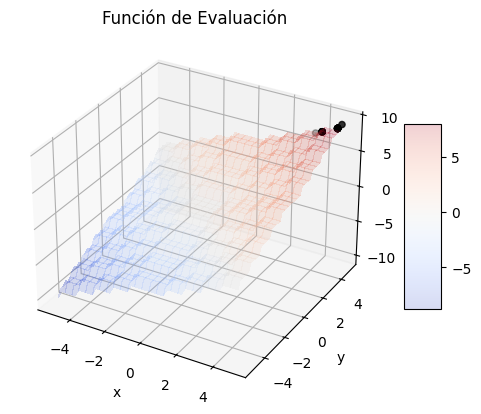

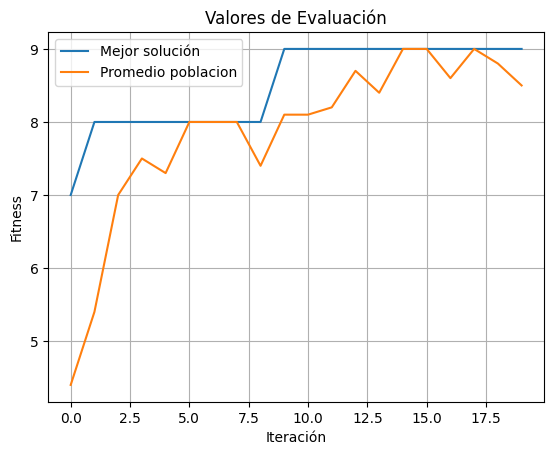

In [ ]:
# @title
Bounds = [[-5.12, 5.12],[-5.12, 5.12]]
Enteras = [False]*len(Bounds)
f = funcion_escalon
cant_individuos = 10
cant_generac = 20
cant_elite = 1
sel = sel_torneo_con_rep
eps = 2
xover = xov_uniform
cant_cruzados = round(0.8 * cant_individuos)
mut = mut_step
cant_mutados = round(0.1 * cant_individuos)

#usar callback = None para que no grafique en cada iteracion y vaya mas rapido
callback = None

Pop = init_pop(cant_individuos, Bounds)
sol, solF, Pop, Fit, traceBest, traceAvg, bestSols = \
    geneticoSimple(Pop, cant_generac, Bounds, Enteras, sel, xover, mut, \
        cant_cruzados, cant_mutados, cant_elite, eps, f, callback)

graficarCaminata(f, bestSols,  Bounds, 0.2, alpha=0.2)

print("Mejor solución: {0} (Fitness: {1})".format(sol, solF))

graficarEvolucionFitness(traceBest, traceAvg)

Prueba usando algoritmo de selección **SUS**:

Mejor solución: [5.0, 4.6] (Fitness: 9)


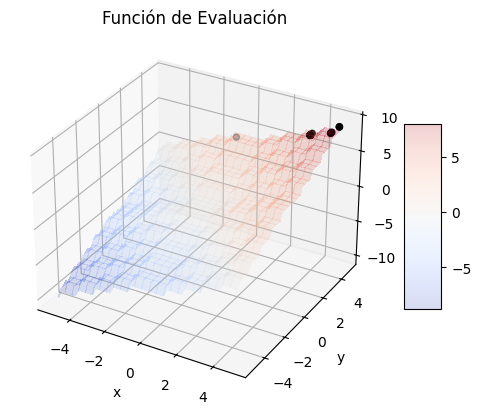

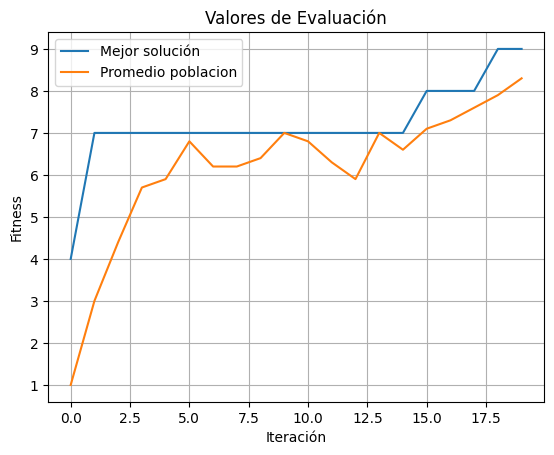

In [ ]:
# @title
Bounds = [[-5.12, 5.12],[-5.12, 5.12]]
Enteras = [False]*len(Bounds)
f = funcion_escalon
cant_individuos = 10
cant_generac = 20
cant_elite = 1
sel = sel_sus
eps = 0.2
xover = xov_uniform
cant_cruzados = round(0.8 * cant_individuos)
mut = mut_step
cant_mutados = round(0.1 * cant_individuos)

#usar callback = None para que no grafique en cada iteracion y vaya mas rapido
callback = None

Pop = init_pop(cant_individuos, Bounds)
sol, solF, Pop, Fit, traceBest, traceAvg, bestSols = \
    geneticoSimple(Pop, cant_generac, Bounds, Enteras, sel, xover, mut, \
        cant_cruzados, cant_mutados, cant_elite, eps, f, callback)

graficarCaminata(f, bestSols,  Bounds, 0.2, alpha=0.2)

print("Mejor solución: {0} (Fitness: {1})".format(sol, solF))

graficarEvolucionFitness(traceBest, traceAvg)

### Comparación de distintas combinaciones de operadores de selección, cruzamiento y mutación en la implementación de un AG para encontrar el óptimo global de una **función escalón**

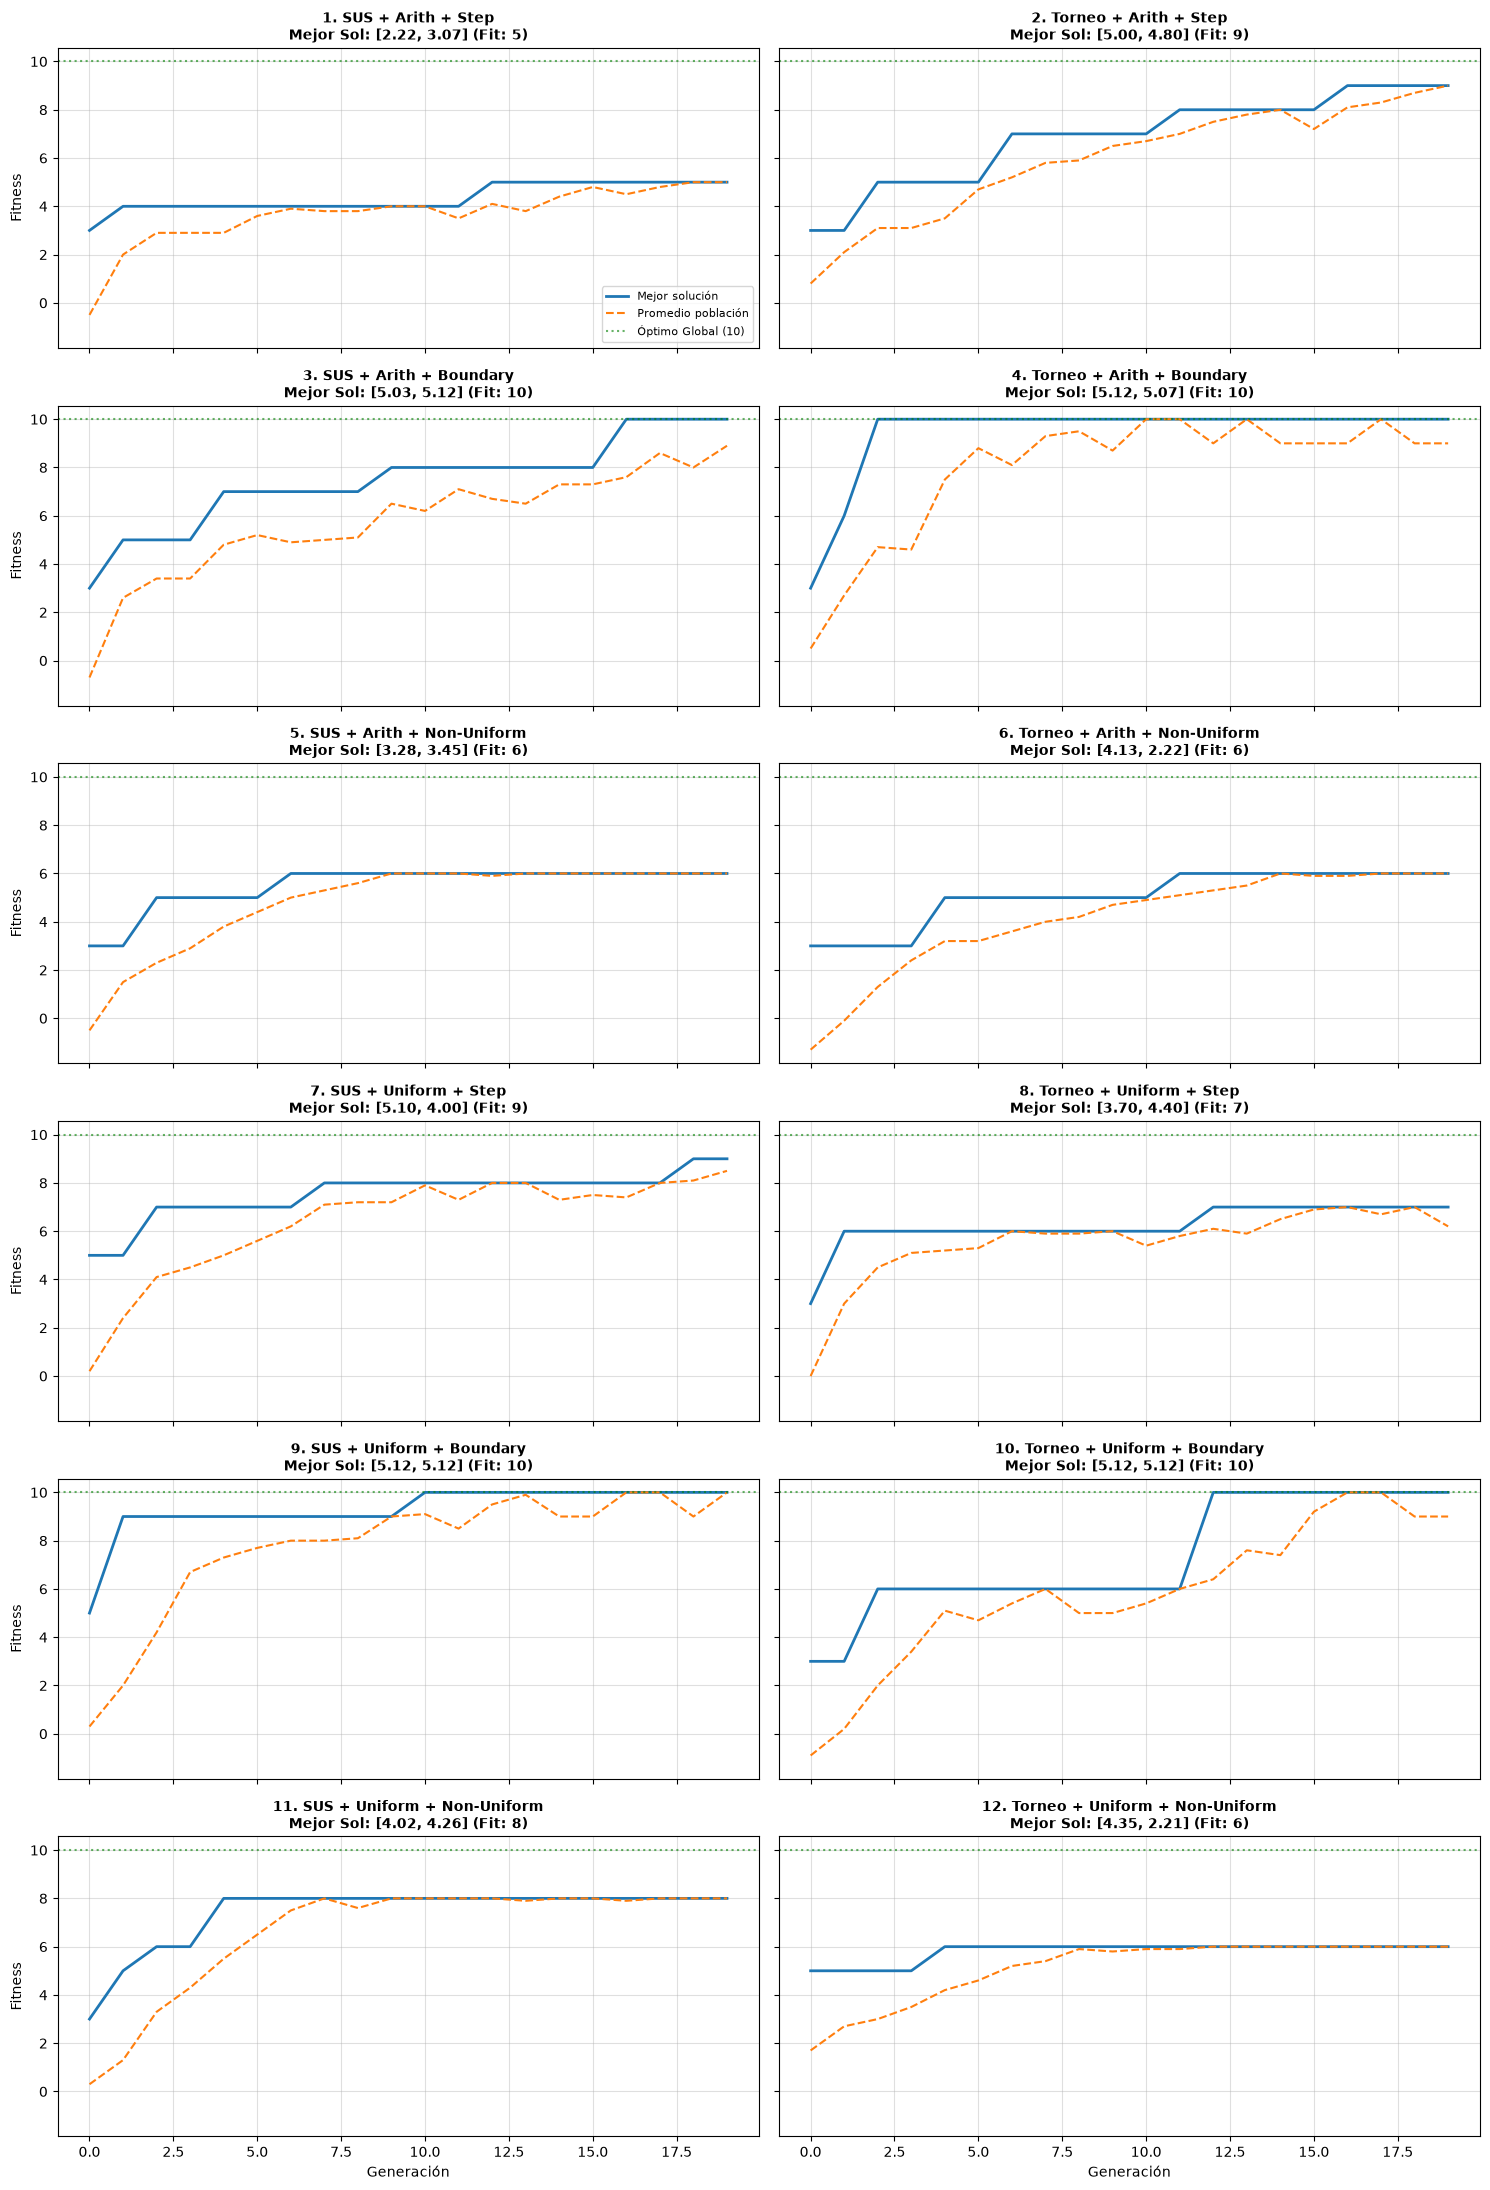

,Combinación,Fit (Misma Pop Inicial),Fit Promedio (30 corridas),Fit Máx,% Éxito Óptimo (=10),% Éxito Alto (>=8)
0,1. SUS + Arith + Step,5,8.73,10,20.0%,96.7%
1,2. Torneo + Arith + Step,9,8.37,10,6.7%,83.3%
2,3. SUS + Arith + Boundary,10,9.93,10,93.3%,100.0%
3,4. Torneo + Arith + Boundary,10,9.93,10,96.7%,100.0%
4,5. SUS + Arith + Non-Uniform,6,6.20,10,3.3%,16.7%
5,6. Torneo + Arith + Non-Uniform,6,6.93,8,0.0%,26.7%
6,7. SUS + Uniform + Step,9,9.00,10,30.0%,100.0%
7,8. Torneo + Uniform + Step,7,9.33,10,36.7%,100.0%
8,9. SUS + Uniform + Boundary,10,9.90,10,96.7%,96.7%
9,10. Torneo + Uniform + Boundary,10,10.00,10,100.0%,100.0%


In [ ]:
import pandas as pd

# Configuración base del Ejercicio 1
Bounds = [[-5.12, 5.12], [-5.12, 5.12]]
Enteras = [False] * len(Bounds)
f = funcion_escalon
cant_individuos = 10
cant_generac = 20
cant_elite = 1
cant_cruzados = round(0.8 * cant_individuos)
cant_mutados = round(0.1 * cant_individuos)

# Definición de las 12 combinaciones solicitadas
combinaciones = [
    ("1. SUS + Arith + Step",                  sel_sus,            0.2, xov_arith,   mut_step),
    ("2. Torneo + Arith + Step",               sel_torneo_con_rep, 2,   xov_arith,   mut_step),
    ("3. SUS + Arith + Boundary",              sel_sus,            0.2, xov_arith,   mut_boundary),
    ("4. Torneo + Arith + Boundary",           sel_torneo_con_rep, 2,   xov_arith,   mut_boundary),
    ("5. SUS + Arith + Non-Uniform",           sel_sus,            0.2, xov_arith,   mut_non_uniform),
    ("6. Torneo + Arith + Non-Uniform",        sel_torneo_con_rep, 2,   xov_arith,   mut_non_uniform),
    ("7. SUS + Uniform + Step",                sel_sus,            0.2, xov_uniform, mut_step),
    ("8. Torneo + Uniform + Step",             sel_torneo_con_rep, 2,   xov_uniform, mut_step),
    ("9. SUS + Uniform + Boundary",            sel_sus,            0.2, xov_uniform, mut_boundary),
    ("10. Torneo + Uniform + Boundary",        sel_torneo_con_rep, 2,   xov_uniform, mut_boundary),
    ("11. SUS + Uniform + Non-Uniform",        sel_sus,            0.2, xov_uniform, mut_non_uniform),
    ("12. Torneo + Uniform + Non-Uniform",     sel_torneo_con_rep, 2,   xov_uniform, mut_non_uniform),
]

# Semilla fija para generar UNA población inicial común y hacer justa la comparativa visual
random.seed(42)
Pop_inicial_base = init_pop(cant_individuos, Bounds)

resultados_tabla = []
fig, axes = plt.subplots(6, 2, figsize=(15, 22), sharex=True, sharey=True)
axes = axes.flatten()

repeticiones_estadistica = 30 # Corridas para evaluar consistencia de cada combinación

for idx, (nombre, sel_fn, param_sel, xov_fn, mut_fn) in enumerate(combinaciones):
    # 1) Ejecución representativa partiendo de la misma población inicial para graficar
    Pop_copia = [ind.copy() for ind in Pop_inicial_base]
    sol, solF, Pop_fin, Fit_fin, traceBest, traceAvg, bestSols = geneticoSimple(
        Pop_copia, cant_generac, Bounds, Enteras,
        sel_fn, xov_fn, mut_fn,
        cant_cruzados, cant_mutados, cant_elite, param_sel, f, callback=None
    )
    
    # Graficar evolución en la subgrilla correspondiente
    ax = axes[idx]
    ax.plot(range(len(traceBest)), traceBest, label='Mejor solución', color='tab:blue', linewidth=2)
    ax.plot(range(len(traceAvg)), traceAvg, label='Promedio población', color='tab:orange', linestyle='--')
    ax.axhline(10, color='green', linestyle=':', alpha=0.6, label='Óptimo Global (10)')
    ax.set_title(f"{nombre}\nMejor Sol: [{sol[0]:.2f}, {sol[1]:.2f}] (Fit: {solF})", fontsize=10, fontweight='bold')
    ax.grid(True, alpha=0.4)
    if idx % 2 == 0:
        ax.set_ylabel("Fitness")
    if idx >= 10:
        ax.set_xlabel("Generación")
    if idx == 0:
        ax.legend(loc='lower right', fontsize=8)

    # 2) Validación estadística en N corridas aleatorias para medir robustez
    fits_corridas = []
    exitos_optimo = 0 # Veces que llega al óptimo global 10 (ambas variables >= 5.0)
    exitos_cercano = 0 # Veces que llega a >= 8
    for _ in range(repeticiones_estadistica):
        P_rand = init_pop(cant_individuos, Bounds)
        _, sF, _, _, _, _, _ = geneticoSimple(
            P_rand, cant_generac, Bounds, Enteras,
            sel_fn, xov_fn, mut_fn,
            cant_cruzados, cant_mutados, cant_elite, param_sel, f, callback=None
        )
        fits_corridas.append(sF)
        if sF == 10:
            exitos_optimo += 1
        if sF >= 8:
            exitos_cercano += 1

    resultados_tabla.append({
        "Combinación": nombre,
        "Fit (Misma Pop Inicial)": solF,
        "Fit Promedio (30 corridas)": round(np.mean(fits_corridas), 2),
        "Fit Máx": np.max(fits_corridas),
        "% Éxito Óptimo (=10)": f"{(exitos_optimo / repeticiones_estadistica)*100:.1f}%",
        "% Éxito Alto (>=8)": f"{(exitos_cercano / repeticiones_estadistica)*100:.1f}%"
    })

plt.tight_layout()
plt.show()

# Mostrar resumen estadístico en tabla
df_resultados = pd.DataFrame(resultados_tabla)
display(df_resultados)

### Conclusiones sobre la influencia de los operadores de **Selección** utilizados
Manteniendo constantes los demás parámetros del algoritmo genético, cambiar el método de selección puede modificar la evolución del mejor fitness y del  promedio de la población. Sin embargo, los resultados de una ejecución aislada no permiten concluir que un método como SUS sea superior a la selección por torneo.

El algoritmo es estocástico, pero no puramente aleatorio: la selección orienta la búsqueda utilizando el fitness. Para comparar ambos métodos de manera más confiable, sería necesario realizar múltiples ejecuciones, utilizando poblaciones iniciales equivalentes y el mismo presupuesto de evaluaciones, y comparar el fitness final promedio, su dispersión y la frecuencia con que se alcanza el óptimo.

En términos de complejidad temporal, si la cantidad de individuos seleccionados es proporcional al tamaño de la población $𝑁$, tanto SUS como la selección por torneo con tamaño $𝑘$ constante presentan un costo de $𝑂(𝑁)$ por etapa de selección. Por lo tanto, no corresponde afirmar que torneo escala mejor que SUS únicamente a partir de este análisis. Si el tamaño del torneo crece proporcionalmente a la población, su costo aumenta a $O(N^2)$.

### Conclusiones sobre la influencia de los operadores de **Cruzamiento** y **Mutación** utilizados

1. ***Boundary Mutation*** destaca en la Función Escalón (combinaciones 3, 4, 9 y 10).
- En este problema en particular, el óptimo global ($F = 10$) se encuentra exactamente en la esquina superior derecha del dominio: $x \in [5.0, 5.12]$ e $y \in [5.0, 5.12]$
- Como Boundary Mutation reemplaza directamente una coordenada por uno de los extremos (-5.12 o +5.12) con probabilidad $0.5$ (por usar `random.randint(0,1)`), cada vez que elige el límite superior inyecta un gen con valor 5.12 (cuyo escalón vale 5, el máximo posible). Combinado con ***Uniform Crossover*** (Combinaciones 9 y 10), otro individuo que tenga 5.12 en la otra coordenada se cruza e inmediatamente alcanzan el óptimo global 10.
2. Pequeña ventaja de ***Uniform Crossover*** (7 a 12) sobre ***Arith Crossover*** (1 a 6).
- En Arith Crossover, los hijos son un promedio ponderado de los padres ($a P_1 + (1-a) P_2$). Esto tiende a "tirar" las coordenadas hacia el centro del espacio ($0, 0$) y dificulta llegar a la esquina extrema $[5.0, 5.12]$ a menos que el operador de mutación empuje fuertemente las variables hacia el borde superior.
- En Uniform Crossover, si el individuo $A$ logra un valor alto en $x$ (ej. $[5.05, 1.2]$) y el individuo $B$ logra un valor alto en $y$ (ej. $[0.5, 5.10]$), el cruzamiento uniforme puede combinar directamente ambas coordenadas intactas para formar el hijo $[5.05, 5.10]$ de fitness 10 sin promediarlas ni degradarlas.
3. Tanto ***Non-Uniform Mutation*** (5, 6, 11 y 12) como ***Step Mutation*** (1, 2, 7 y 8) tienen una pobre eficacia para lograr el óptimo global.
- En las primeras generaciones ($t \ll T$), Non-Uniform Mutation da saltos amplios hacia los bordes (comportándose parecido a Step Mutation), lo que le permite subir rápido de escalón.
- En las últimas generaciones ($t \to T$), Non-Uniform Mutation reduce el tamaño de paso a valores cercanos a cero, estabilizando el promedio de la población (traceAvg se vuelve más suave y cercano a traceBest), mientras que Step Mutation sigue dando saltos uniformes grandes que pueden bajar a un individuo de escalón en las iteraciones finales; a pesar de que con esto último se pueda insinuar de que hay una ventaja de Non_Uniform Mutation, hay que destacar que, si el AG toma un camino que no está aproximadamente dirigido al óptimo global, se estancará en un área no óptima con el paso de las generaciones.


## Ejercicio 2

Utilizando el código del Algoritmo Genético del punto anterior, búsque el óptimo global de las siguientes funciones:

- G(x, y) = -20 -[x^2+y^2] + 10*[cos(𝜋x)+cos(𝜋y)], x,y ∈ [-5.12, 5.12]
- F2(x,y) = -100(x^2-y)^2 - (1-x)^2, x,y ∈ [-2.048, 2.048]

En cada caso se pide:
1. Ajuste adecuadamente los parámetros del algoritmo de manera de asegurar que encuentre el óptimo global en más del 80% de las ejecuciones. Considere dos cifras decimales de precisión para determinar que llegó al óptimo.
2. Grafique los individuos de la población final en el plano.
3. Generar un gráfico con los valores de fitness de las soluciones encontradas en cada generación y saque conclusiones de su comportamiento al variar los valores de los parámetros.


***Función de Rastrigin:*** (ver tasa de éxito de pruebas en función ***validar_tasa_exito***, justo antes del Ejercicio 3)

Con Operador de selección **SUS**:
- Tamaño de población (cant_individuos): 35
- Cantidad de generaciones (cant_generac): 40
- Elitismo (cant_elite): 1
- Operador de selección (sel): sel_sus
- Parámetro de escala (eps): 0.20
- Operador de cruce (xover): xov_arith
- Individuos cruzados (cant_cruzados): 28 (80%)
- Operador de mutación (mut): mut_step
- Individuos mutados (cant_mutados): 5 (15%)

Con Operador de selección **Torneo Con Reposición**:
- Tamaño de población (cant_individuos): 45
- Cantidad de generaciones (cant_generac): 45
- Elitismo (cant_elite): 2
- Operador de selección (sel): sel_torneo_con_rep
- Tamaño de torneo (eps): 2
- Operador de cruce (xover): xov_arith
- Individuos cruzados (cant_cruzados): 36 (80%)
- Operador de mutación (mut): mut_step
- Individuos mutados (cant_mutados): 7 (15%)

Mejor solución: [-0.001408659878061419, -0.0006746439744873527]
Fitness obtenido: -0.00012270015054838268


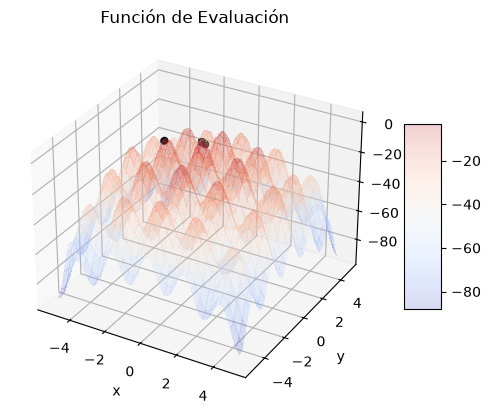

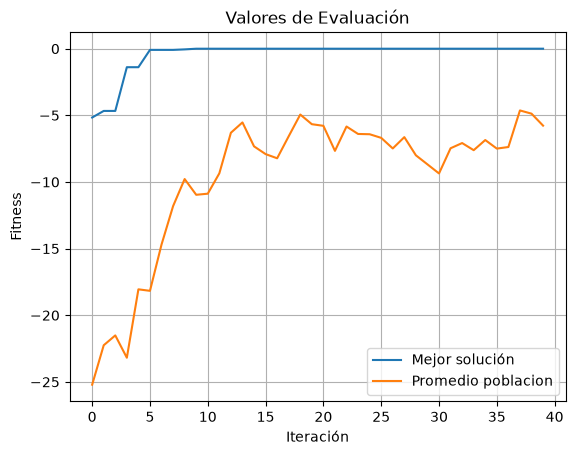

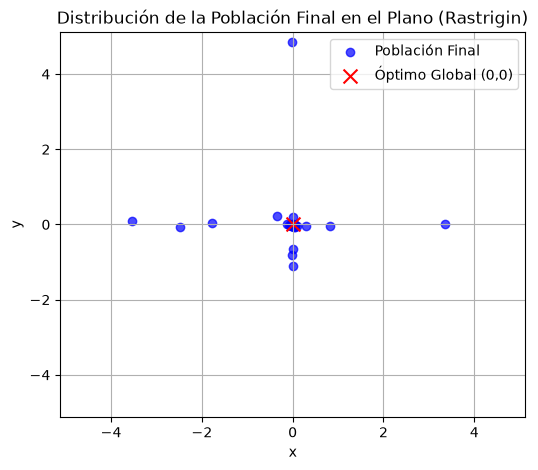

In [7]:
# @title
def rastriguin(X_vars):
  # Mira como nos calzaron un 3.14 en vez de usar Math.pi
    return -20 - sum([xi**2 for xi in X_vars]) + 10*sum([math.cos(3.14*xi) for xi in X_vars])

Bounds = [[-5.12, 5.12], [-5.12, 5.12]]
Enteras = [False] * len(Bounds)
f = rastriguin

cant_individuos = 35
cant_generac    = 40
cant_elite      = 1
sel             = sel_sus
eps             = 0.20
xover           = xov_arith
cant_cruzados   = round(0.80 * cant_individuos)  # 28
mut             = mut_step
cant_mutados    = round(0.15 * cant_individuos)  # 5
callback        = None

Pop = init_pop(cant_individuos, Bounds)
sol, solF, Pop, Fit, traceBest, traceAvg, bestSols = \
    geneticoSimple(Pop, cant_generac, Bounds, Enteras, sel, xover, mut, \
        cant_cruzados, cant_mutados, cant_elite, eps, f, callback)

print("Mejor solución:", sol)
print("Fitness obtenido:", solF)

# 1. Gráfica 3D / Contorno con la trayectoria de mejores soluciones
graficarCaminata(f, bestSols, Bounds, 0.1, alpha=0.2)

# 2. Gráfica de evolución del fitness por generación (Item 3)
graficarEvolucionFitness(traceBest, traceAvg)

# 3. Gráfica de la población final en el plano XY (Item 2)
plt.figure(figsize=(6, 5))
x_pop = [ind[0] for ind in Pop]
y_pop = [ind[1] for ind in Pop]
plt.scatter(x_pop, y_pop, c='blue', alpha=0.7, label='Población Final')
plt.scatter([0], [0], c='red', marker='x', s=100, label='Óptimo Global (0,0)')
plt.xlim(Bounds[0])
plt.ylim(Bounds[1])
plt.title("Distribución de la Población Final en el Plano (Rastrigin)")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)
plt.legend()
plt.show()

***Función de Rosenbrock (F2​):***

Con Operador de selección **SUS**:
- Tamaño de población (cant_individuos): 85
- Cantidad de generaciones (cant_generac): 95
- Elitismo (cant_elite): 3
- Operador de selección (sel): sel_sus
- Parámetro de escala (eps): 0.02
- Operador de cruce (xover): xov_arith
- Individuos cruzados (cant_cruzados): 72 (85%)
- Operador de mutación (mut): mut_step
- Individuos mutados (cant_mutados): 9 (10%)

Con Operador de selección **Torneo Con Reposición**:
- Tamaño de población (cant_individuos): 110
- Cantidad de generaciones (cant_generac): 160
- Elitismo (cant_elite): 4
- Operador de selección (sel): sel_torneo_con_rep
- Tamaño de torneo (eps): 2
- Operador de cruce (xover): xov_arith
- Individuos cruzados (cant_cruzados): 94 (85%)
- Operador de mutación (mut): mut_step
- Individuos mutados (cant_mutados): 13 (12%)

Mejor solución: [1.0001957061273363, 1.000412029540219]
Fitness obtenido: -8.065034923292127e-08


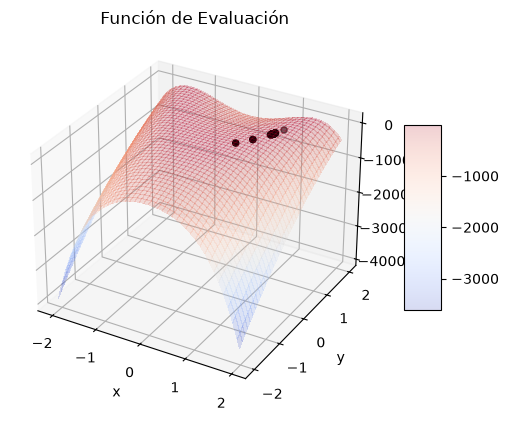

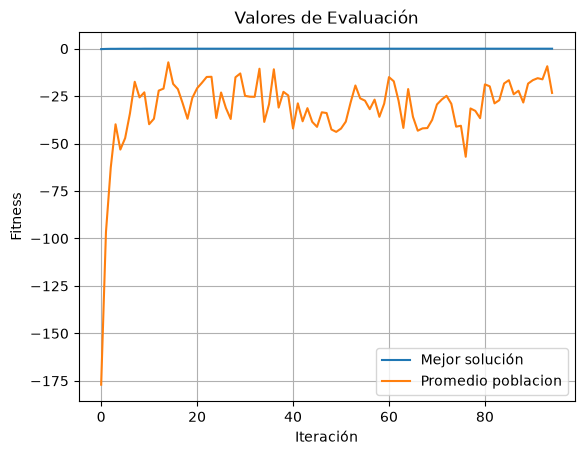

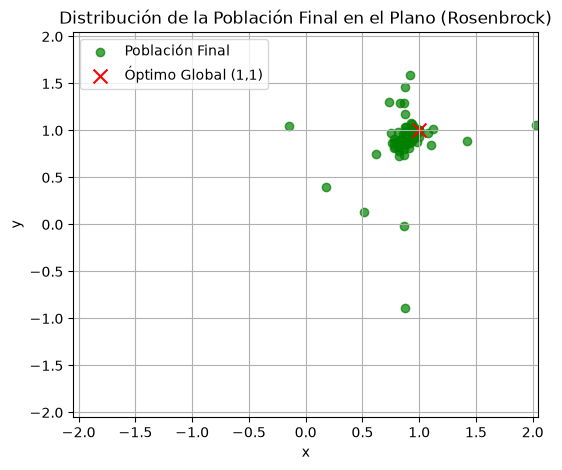

In [8]:
# @title
def F2(X_vars):
    return -100*(X_vars[0]**2 - X_vars[1])**2 - (1 - X_vars[0])**2

Bounds = [[-2.048, 2.048], [-2.048, 2.048]]
Enteras = [False] * len(Bounds)
f = F2

cant_individuos = 85
cant_generac    = 95
cant_elite      = 3
sel             = sel_sus
eps             = 0.02
xover           = xov_arith
cant_cruzados   = round(0.85 * cant_individuos)  # 72
mut             = mut_step
cant_mutados    = round(0.10 * cant_individuos)  # 8 o 9
callback        = None

Pop = init_pop(cant_individuos, Bounds)
sol, solF, Pop, Fit, traceBest, traceAvg, bestSols = \
    geneticoSimple(Pop, cant_generac, Bounds, Enteras, sel, xover, mut, \
        cant_cruzados, cant_mutados, cant_elite, eps, f, callback)

print("Mejor solución:", sol)
print("Fitness obtenido:", solF)

# 1. Gráfica 3D / Contorno
graficarCaminata(f, bestSols, Bounds, 0.05, alpha=0.2)

# 2. Gráfica de evolución del fitness por generación (Item 3)
graficarEvolucionFitness(traceBest, traceAvg)

# 3. Gráfica de la población final en el plano XY (Item 2)
plt.figure(figsize=(6, 5))
x_pop = [ind[0] for ind in Pop]
y_pop = [ind[1] for ind in Pop]
plt.scatter(x_pop, y_pop, c='green', alpha=0.7, label='Población Final')
plt.scatter([1], [1], c='red', marker='x', s=100, label='Óptimo Global (1,1)')
plt.xlim(Bounds[0])
plt.ylim(Bounds[1])
plt.title("Distribución de la Población Final en el Plano (Rosenbrock)")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)
plt.legend()
plt.show()

### Comparación de distintas combinaciones de operadores de selección, cruzamiento y mutación en la implementación de un AG para encontrar el óptimo global de las funciones **Rastrigin** y **Rosenbrock**

In [12]:
import pandas as pd

def evaluar_12_combinaciones_ej2(nombre_problema, f_obj, Bounds, config_sus, config_torneo, repeticiones=50):
    Enteras = [False] * len(Bounds)
    
    # Definición de las 12 combinaciones (Nombre, Función Selección, Tipo Config, Cruzamiento, Mutación)
    combinaciones = [
        ("1. SUS + Arith + Step",              sel_sus,            config_sus,    xov_arith,   mut_step),
        ("2. Torneo + Arith + Step",           sel_torneo_con_rep, config_torneo, xov_arith,   mut_step),
        ("3. SUS + Arith + Boundary",          sel_sus,            config_sus,    xov_arith,   mut_boundary),
        ("4. Torneo + Arith + Boundary",       sel_torneo_con_rep, config_torneo, xov_arith,   mut_boundary),
        ("5. SUS + Arith + Non-Uniform",       sel_sus,            config_sus,    xov_arith,   mut_non_uniform),
        ("6. Torneo + Arith + Non-Uniform",    sel_torneo_con_rep, config_torneo, xov_arith,   mut_non_uniform),
        ("7. SUS + Uniform + Step",            sel_sus,            config_sus,    xov_uniform, mut_step),
        ("8. Torneo + Uniform + Step",         sel_torneo_con_rep, config_torneo, xov_uniform, mut_step),
        ("9. SUS + Uniform + Boundary",        sel_sus,            config_sus,    xov_uniform, mut_boundary),
        ("10. Torneo + Uniform + Boundary",    sel_torneo_con_rep, config_torneo, xov_uniform, mut_boundary),
        ("11. SUS + Uniform + Non-Uniform",    sel_sus,            config_sus,    xov_uniform, mut_non_uniform),
        ("12. Torneo + Uniform + Non-Uniform", sel_torneo_con_rep, config_torneo, xov_uniform, mut_non_uniform),
    ]
    
    resultados = []
    fig, axes = plt.subplots(6, 2, figsize=(15, 22), sharex=False, sharey=False)
    axes = axes.flatten()
    fig.suptitle(f"Evolución de Fitness por Combinación - {nombre_problema}", fontsize=16, fontweight='bold', y=1.01)

    for idx, (nombre, sel_fn, cfg, xov_fn, mut_fn) in enumerate(combinaciones):
        cant_ind = cfg['cant_individuos']
        cant_gen = cfg['cant_generac']
        cant_eli = cfg['cant_elite']
        param_s  = cfg['eps']
        cant_cru = cfg['cant_cruzados']
        cant_mut = cfg['cant_mutados']
        
        # 1) Corrida con semilla controlada para graficar una curva representativa
        random.seed(42)
        Pop_plot = init_pop(cant_ind, Bounds)
        sol, solF, _, _, traceBest, traceAvg, _ = geneticoSimple(
            Pop_plot, cant_gen, Bounds, Enteras,
            sel_fn, xov_fn, mut_fn,
            cant_cru, cant_mut, cant_eli, param_s, f_obj, callback=None
        )
        
        ax = axes[idx]
        ax.plot(range(len(traceBest)), traceBest, label='Mejor solución', color='tab:blue', linewidth=2)
        ax.plot(range(len(traceAvg)), traceAvg, label='Promedio población', color='tab:orange', linestyle='--', alpha=0.8)
        ax.axhline(0.0, color='green', linestyle=':', alpha=0.7, label='Óptimo Global (0.0)')
        ax.set_title(f"{nombre}\nSol: [{sol[0]:.3f}, {sol[1]:.3f}] | Mejor Fit: {solF:.4f}", fontsize=10, fontweight='bold')
        ax.grid(True, alpha=0.4)
        if idx % 2 == 0:
            ax.set_ylabel("Fitness")
        if idx >= 10:
            ax.set_xlabel("Generación")
        if idx == 0:
            ax.legend(loc='lower right', fontsize=8)
            
        # 2) Evaluación estadística sobre 'repeticiones' corridas independientes
        exitos = 0
        fits_finales = []
        for _ in range(repeticiones):
            Pop_run = init_pop(cant_ind, Bounds)
            _, sF, _, _, _, _, _ = geneticoSimple(
                Pop_run, cant_gen, Bounds, Enteras,
                sel_fn, xov_fn, mut_fn,
                cant_cru, cant_mut, cant_eli, param_s, f_obj, callback=None
            )
            fits_finales.append(sF)
            if sF >= -0.01: # Criterio de 2 cifras decimales respecto al óptimo 0.0
                exitos += 1
                
        tasa_exito = (exitos / repeticiones) * 100
        resultados.append({
            "Combinación": nombre,
            "Pob / Gen": f"{cant_ind} / {cant_gen}",
            "Tasa Éxito (>=-0.01)": f"{tasa_exito:.1f}% ({exitos}/{repeticiones})",
            "Fitness Promedio": round(np.mean(fits_finales), 4),
            "Desvío Estándar": round(np.std(fits_finales), 4),
            "Mejor Fitness": round(np.max(fits_finales), 5)
        })

    plt.tight_layout()
    plt.show()
    
    df = pd.DataFrame(resultados)
    print(f"\n=== TABLA RESUMEN: {nombre_problema.upper()} ({repeticiones} ejecuciones por combinación) ===")
    display(df)
    return df

### Prueba de las 12 combinaciones sobre **Rastrigin**

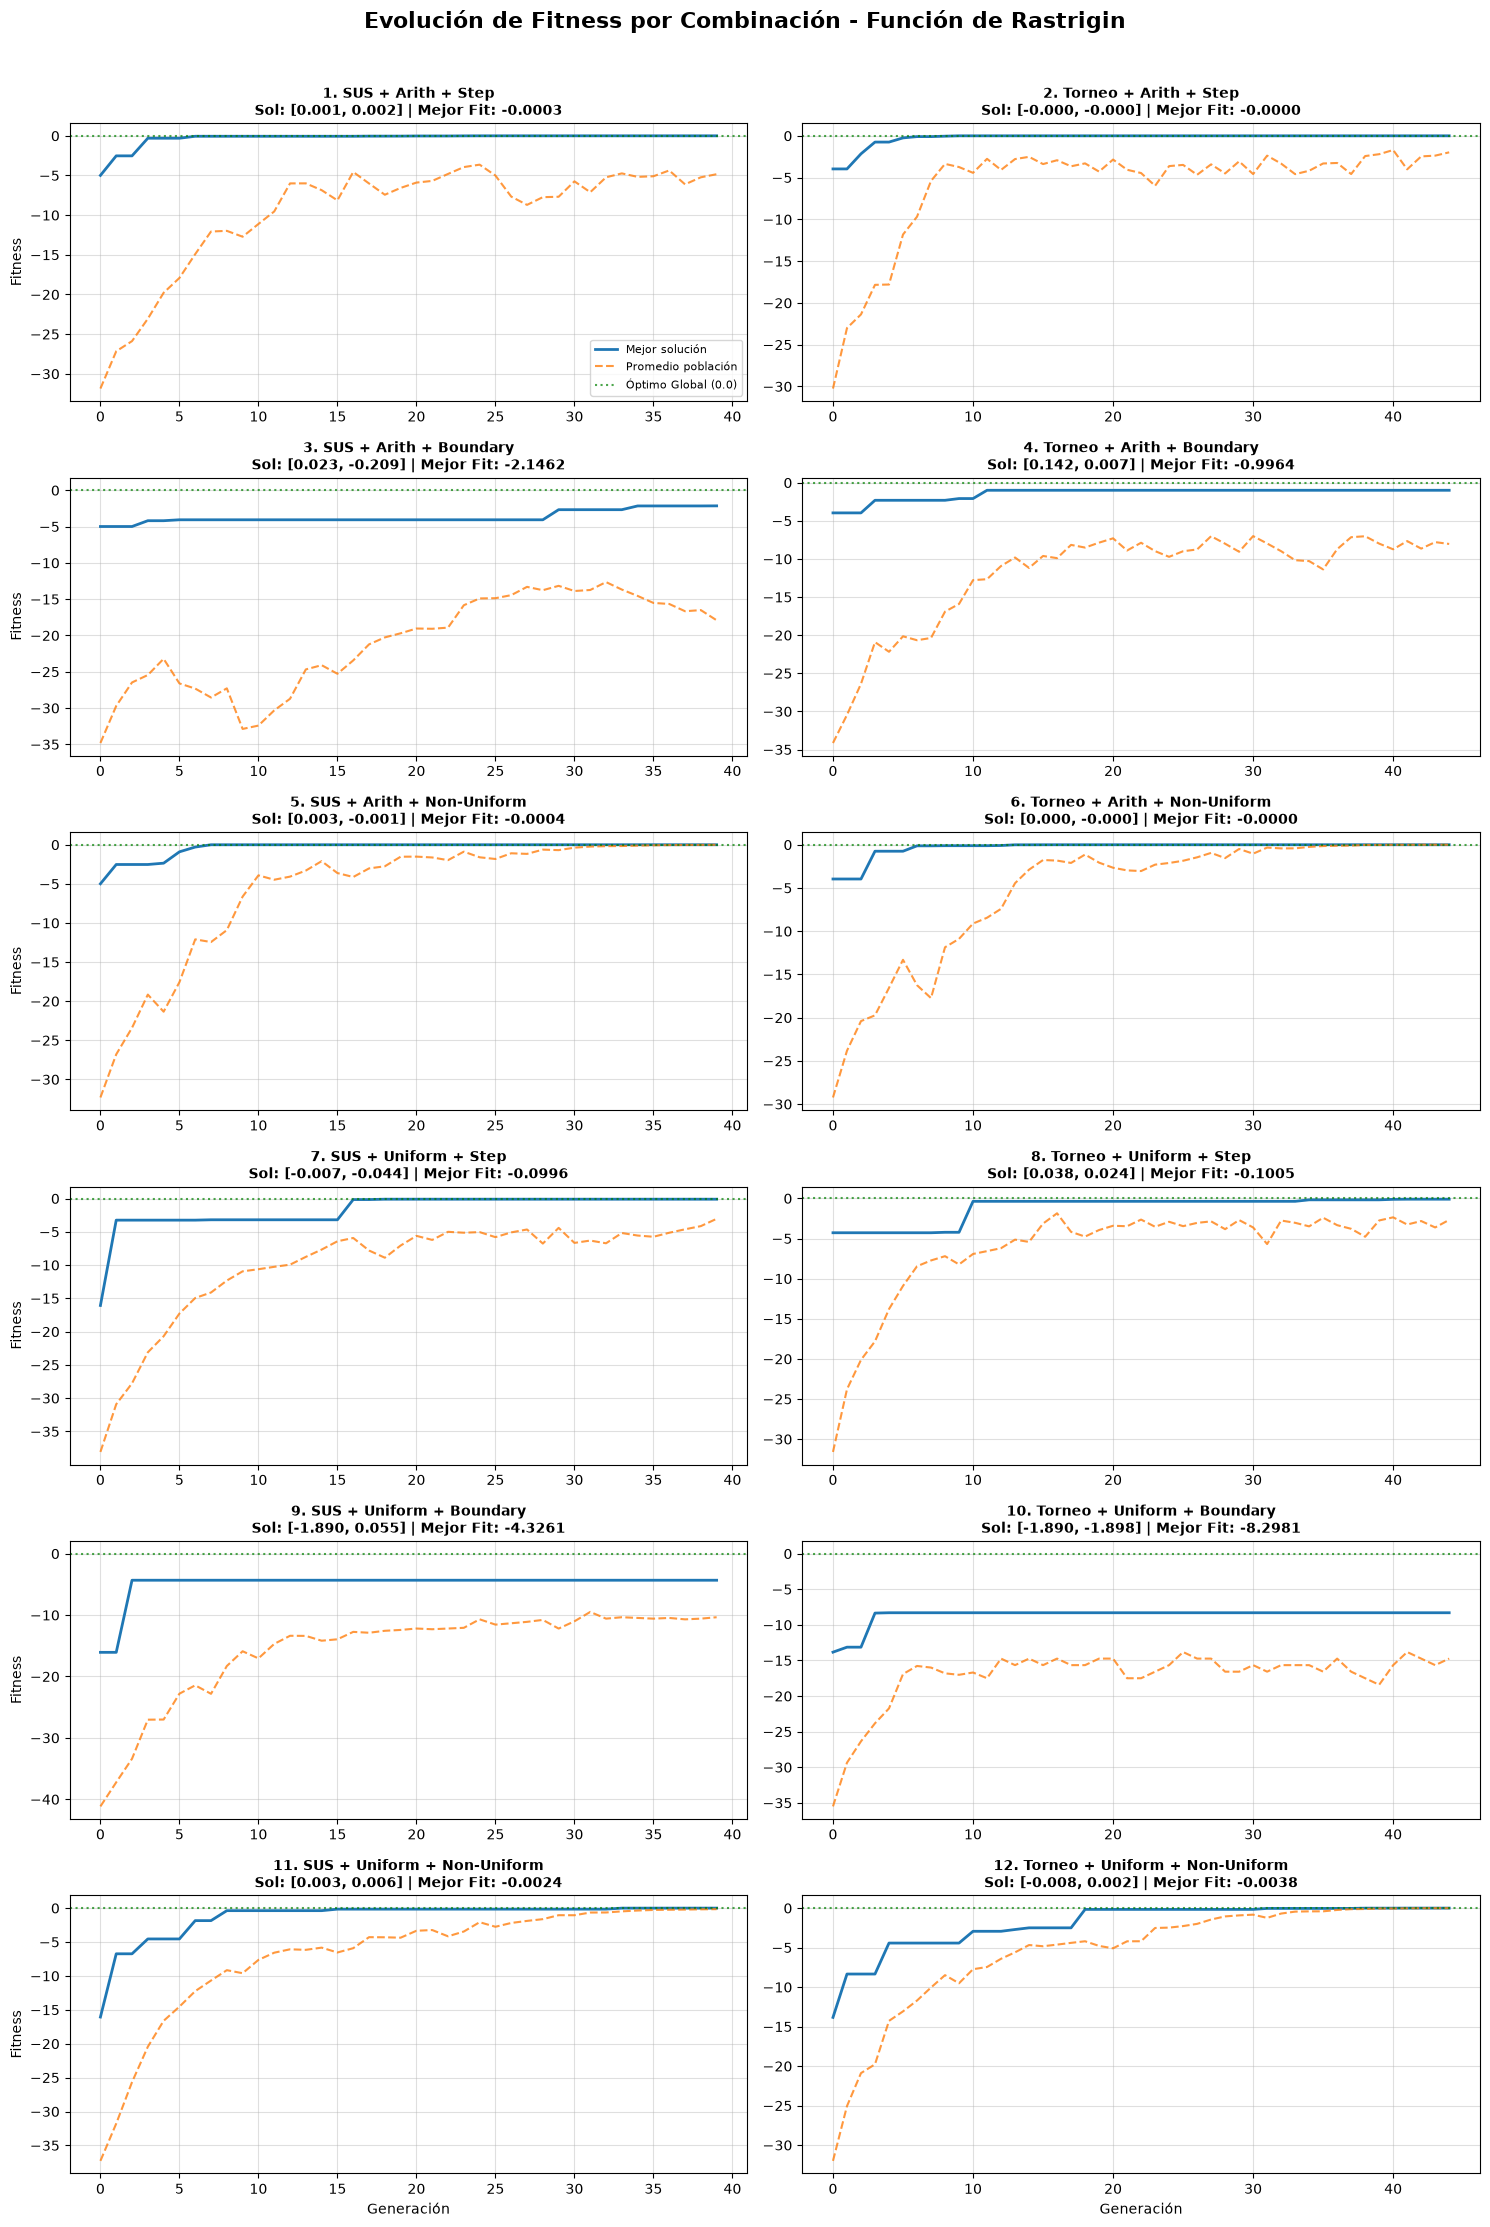


=== TABLA RESUMEN: FUNCIÓN DE RASTRIGIN (50 ejecuciones por combinación) ===


,Combinación,Pob / Gen,Tasa Éxito (>=-0.01),Fitness Promedio,Desvío Estándar,Mejor Fitness
0,1. SUS + Arith + Step,35 / 40,94.0% (47/50),-0.0040,0.0132,-0.00000
1,2. Torneo + Arith + Step,45 / 45,86.0% (43/50),-0.0068,0.0166,0.00000
2,3. SUS + Arith + Boundary,35 / 40,58.0% (29/50),-0.0952,0.2476,-0.00001
3,4. Torneo + Arith + Boundary,45 / 45,74.0% (37/50),-0.1060,0.5581,-0.00000
4,5. SUS + Arith + Non-Uniform,35 / 40,100.0% (50/50),-0.0004,0.0008,-0.00000
5,6. Torneo + Arith + Non-Uniform,45 / 45,100.0% (50/50),-0.0000,0.0001,-0.00000
6,7. SUS + Uniform + Step,35 / 40,0.0% (0/50),-0.4902,0.5857,-0.01871
7,8. Torneo + Uniform + Step,45 / 45,6.0% (3/50),-0.1750,0.2521,-0.00231
8,9. SUS + Uniform + Boundary,35 / 40,2.0% (1/50),-2.9448,2.5827,-0.00223
9,10. Torneo + Uniform + Boundary,45 / 45,0.0% (0/50),-2.9584,2.4887,-0.08753


In [13]:
cfg_ras_sus = {
    'cant_individuos': 35, 'cant_generac': 40, 'cant_elite': 1,
    'eps': 0.20, 'cant_cruzados': round(0.80 * 35), 'cant_mutados': round(0.15 * 35)
}
cfg_ras_torneo = {
    'cant_individuos': 45, 'cant_generac': 45, 'cant_elite': 2,
    'eps': 2, 'cant_cruzados': round(0.80 * 45), 'cant_mutados': round(0.15 * 45)
}

df_rastrigin = evaluar_12_combinaciones_ej2(
    "Función de Rastrigin", rastriguin, [[-5.12, 5.12], [-5.12, 5.12]],
    cfg_ras_sus, cfg_ras_torneo, repeticiones=50
)

### Prueba de las 12 combinaciones sobre **Rosenbrock** (F2)

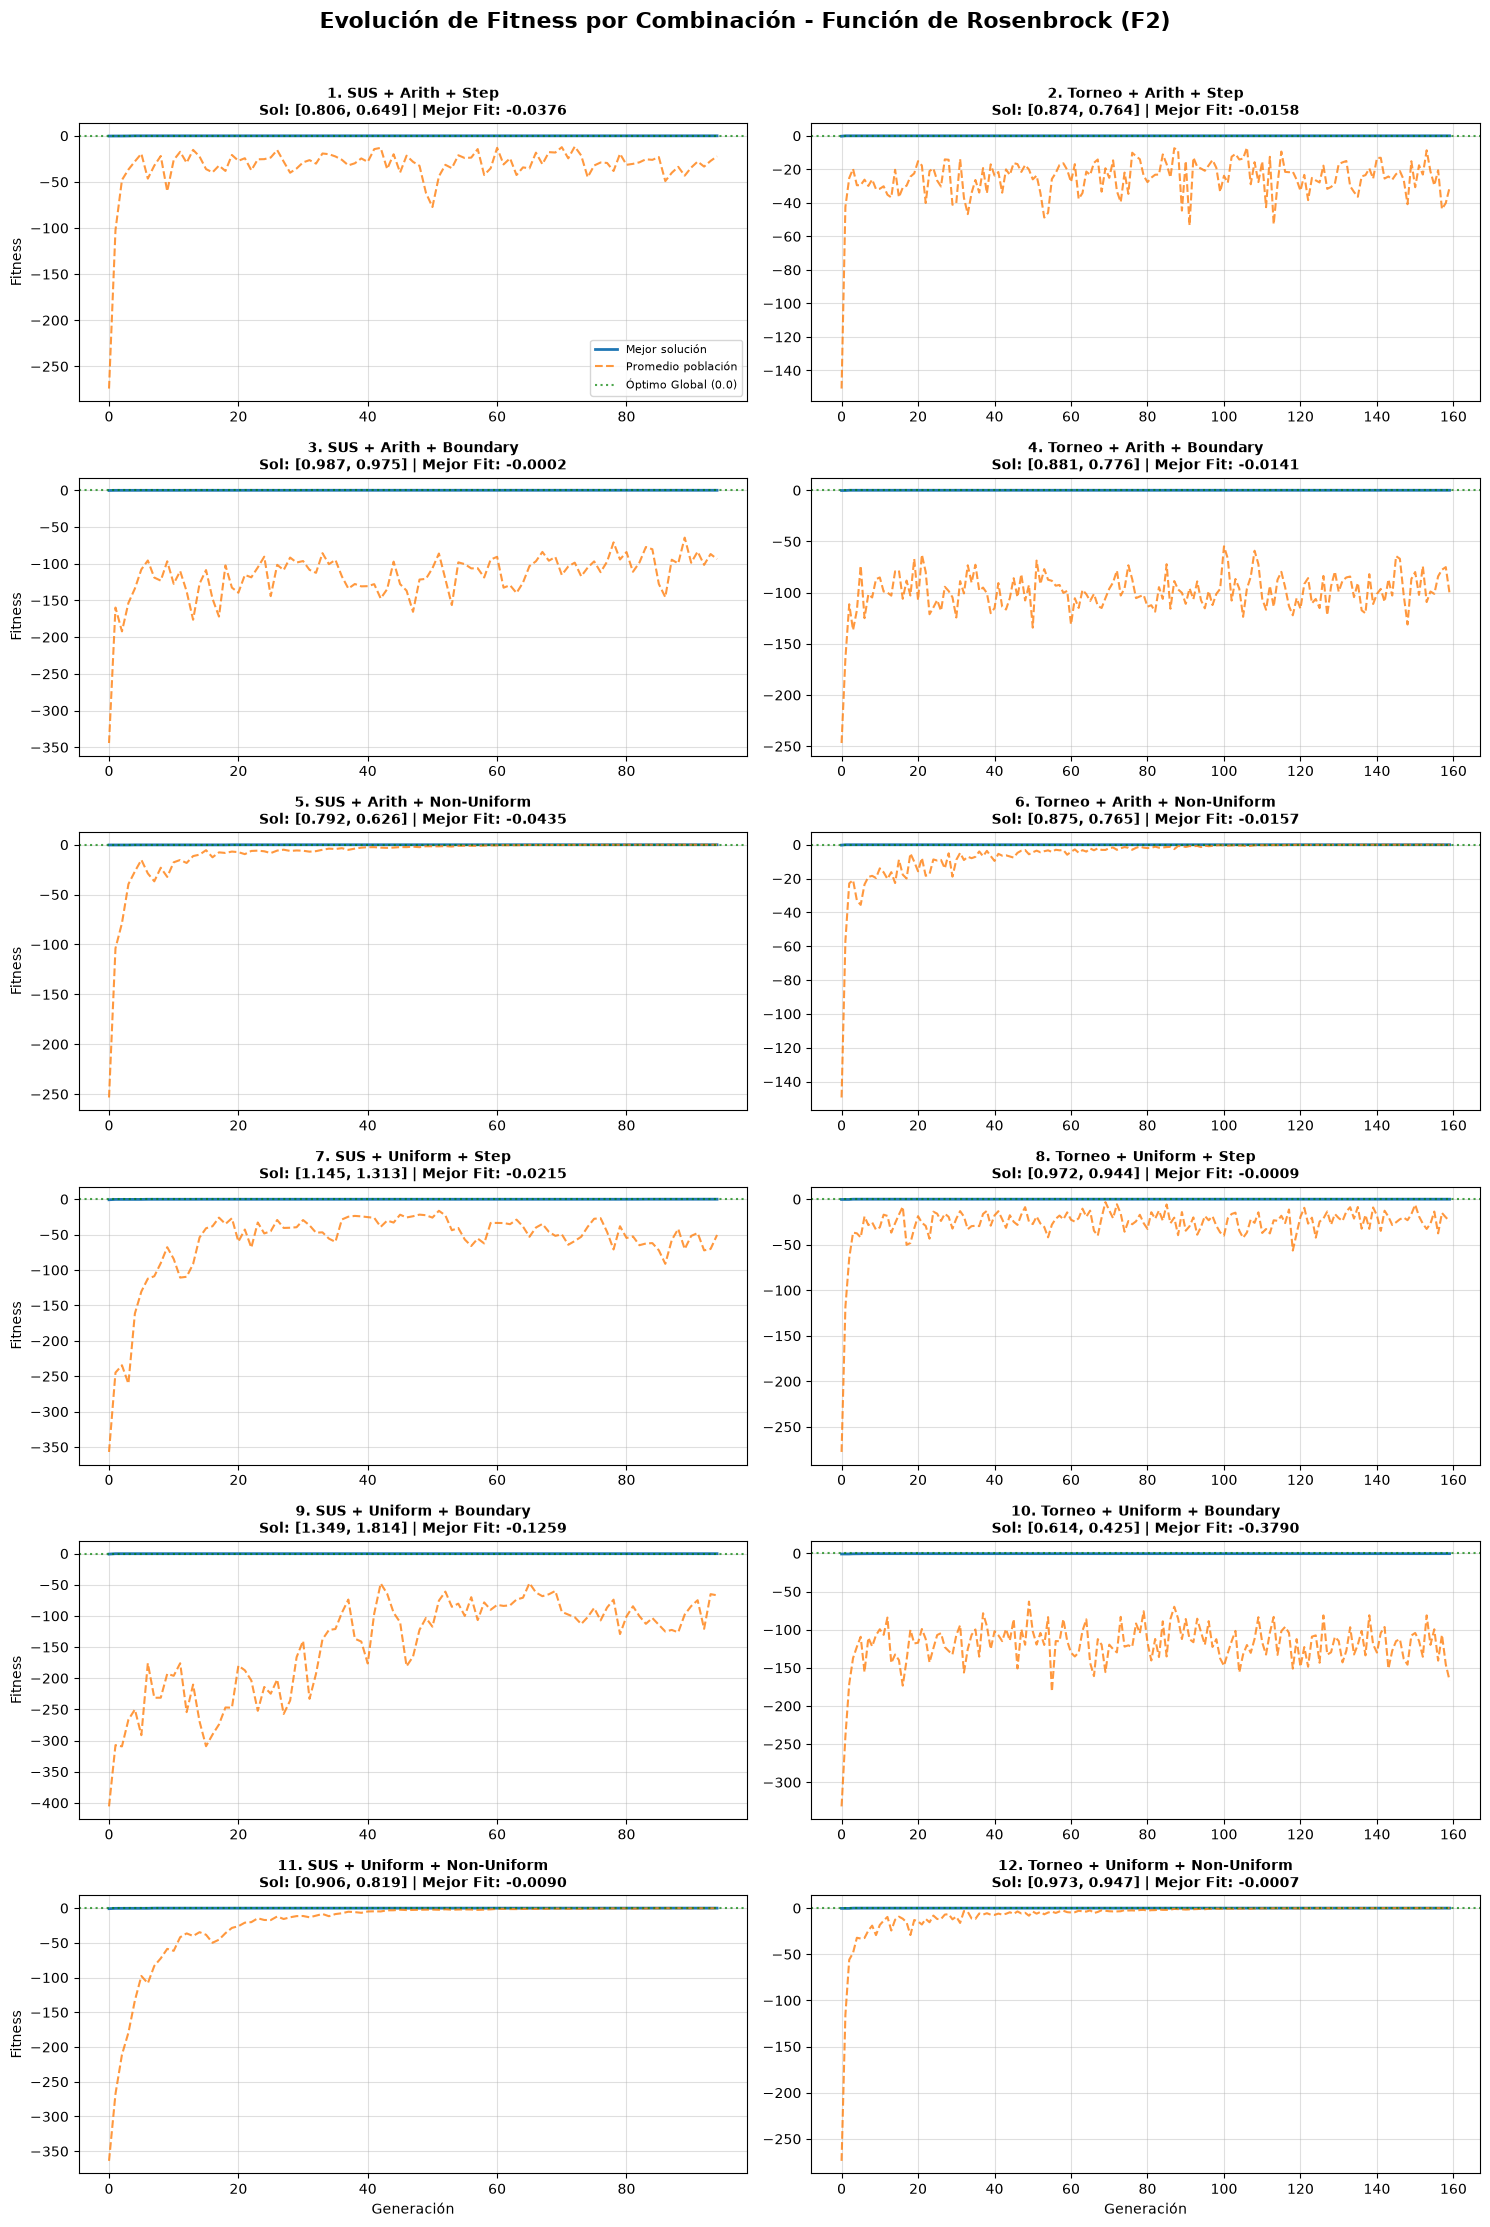


=== TABLA RESUMEN: FUNCIÓN DE ROSENBROCK (F2) (50 ejecuciones por combinación) ===


,Combinación,Pob / Gen,Tasa Éxito (>=-0.01),Fitness Promedio,Desvío Estándar,Mejor Fitness
0,1. SUS + Arith + Step,85 / 95,60.0% (30/50),-0.0156,0.0208,-0.00000
1,2. Torneo + Arith + Step,110 / 160,64.0% (32/50),-0.0211,0.0367,-0.00000
2,3. SUS + Arith + Boundary,85 / 95,94.0% (47/50),-0.0034,0.0055,-0.00000
3,4. Torneo + Arith + Boundary,110 / 160,50.0% (25/50),-0.0369,0.0539,-0.00000
4,5. SUS + Arith + Non-Uniform,85 / 95,62.0% (31/50),-0.0232,0.0352,-0.00000
5,6. Torneo + Arith + Non-Uniform,110 / 160,64.0% (32/50),-0.0207,0.0415,-0.00000
6,7. SUS + Uniform + Step,85 / 95,64.0% (32/50),-0.0119,0.0146,-0.00020
7,8. Torneo + Uniform + Step,110 / 160,40.0% (20/50),-0.0568,0.0903,-0.00008
8,9. SUS + Uniform + Boundary,85 / 95,14.0% (7/50),-0.0919,0.1027,-0.00015
9,10. Torneo + Uniform + Boundary,110 / 160,16.0% (8/50),-0.1397,0.1469,-0.00065


In [14]:
cfg_ros_sus = {
    'cant_individuos': 85, 'cant_generac': 95, 'cant_elite': 3,
    'eps': 0.02, 'cant_cruzados': round(0.85 * 85), 'cant_mutados': round(0.10 * 85)
}
cfg_ros_torneo = {
    'cant_individuos': 110, 'cant_generac': 160, 'cant_elite': 4,
    'eps': 2, 'cant_cruzados': round(0.85 * 110), 'cant_mutados': round(0.12 * 110)
}

df_rosenbrock = evaluar_12_combinaciones_ej2(
    "Función de Rosenbrock (F2)", F2, [[-2.048, 2.048], [-2.048, 2.048]],
    cfg_ros_sus, cfg_ros_torneo, repeticiones=50
)

### Conclusiones sobre la influencia de los operadores de **Cruzamiento** y **Mutación** utilizados
1. Pobre desempeño de ***Boundary Mutation*** (3, 4, 9 y 10).
- En la función escalón del Ejercicio 1, Boundary Mutation era excelente porque el óptimo estaba exactamente en el borde $(5.12, 5.12)$.
- En Rastrigin (óptimo en $(0, 0)$) y Rosenbrock (óptimo en $(1, 1)$), mandar una coordenada a $\pm 5.12$ o $\pm 2.048$ destruye la aptitud del individuo (generando fitness cercanos a $-60$ en Rastrigin o $-1600$ en Rosenbrock). En los gráficos, se puede observar que la curva naranja (promedio de la población) presenta muchas caídas bruscas e incluso, cuando se combina con ***Uniform Crossover*** (combinaciones 9 y 10), la tasa de éxito cae cerca del 0% porque ningún operador puede generar valores nuevos cercanos al óptimo
2. ***Uniform Crossover tiene una limitación*** frente a Arith Crossover ***en espacios continuos***.
- Como Uniform Crossover solo intercambia las coordenadas $x$ e $y$ existentes entre padres sin promediarlas, en Rosenbrock (donde $x$ e $y$ están fuertemente acopladas por la curva $y = x^2$) separar el $x$ de un padre y juntarlo con el $y$ de otro padre saca a los hijos fuera del valle parabólico. En cambio, ***Arith Crossover*** (Combinaciones 1 a 6) interpola sobre el segmento que une a los padres, manteniendo a los descendientes dentro del valle y logrando tasas superiores al 80% con Step y Non-Uniform Mutation.
3. ***Non-Uniform Mutation corre con ventaja*** sobre Step Mutation.
- En las curvas de evolución, con Non-Uniform Mutation la línea naranja (Promedio población) converge hasta pegarse casi por completo a la línea azul (Mejor solución) en las últimas generaciones, logrando un desvío estándar menor y un fitness promedio más cercano a $0.0$. Esto ocurre porque a medida que gen se acerca a cant_generac, el factor $P(\text{gen\_act}/\text{gen\_max})$ reduce la amplitud de las mutaciones, haciendo explotación fina alrededor de $(0, 0)$ o $(1, 1)$ en lugar de seguir tirando pasos grandes hacia los bordes (como hace Step Mutation).

## Ejercicio 3
Dada una cadena binaria de "n" bits, se desea utilizar un AG para encontrar cuál es la solución que agrupe la mayor cantidad de 0s a la izquierda y mayor cantidad de 1s a la derecha. Se pide:
1. Diseñe una función Fitness adecuada para el problema, teniendo en cuenta que las mejores soluciones deben tener un valor más grande que las otras.
2. Utilice el AG del punto anterior para resolver el problema. Para la elección de los operadores, tenga en cuenta que la codificación es binaria.
3. Ajuste los parámetros adecuadamente para resolver el problema tomando n=10, n=20, n=50.
4. En cada caso, grafique la Evolución de los valores de fitness en cada generación.

In [ ]:
# @title
# Funciones para graficar
import matplotlib.pyplot as plt

def graficarEvolucionFitness(best, mean):
    """Método para graficar la evolucion del fitness con las iteraciones.
    Parametros
    best, mean : list. Lista con los valores de evaluación de la mejor y peor solución.
    """
    fig = plt.figure()
    ax = plt.axes()
    x = range(len(best));
    plt.plot(x, best, label='Mejor solución');
    plt.plot(x, mean, label='Promedio poblacion');
    plt.title('Valores de Evaluación')
    plt.xlabel('Iteración')
    plt.ylabel('Fitness')
    plt.grid()
    plt.legend()

def callback_print(Pop, Fit, gen, cant_generac, params):
    mejor_idx = max(range(len(Fit)), key=lambda i: Fit[i])
    mejor_fit = Fit[mejor_idx]
    promedio = sum(Fit) / len(Fit)

    print(
        f"Gen. {gen}/{cant_generac} | "
        f"Mejor: {mejor_fit} | "
        f"Promedio: {promedio:.2f}"
    )
    print("Mejor cadena:", Pop[mejor_idx])

    return params

In [312]:
# @title
# Por uan decisión técnica en vez de utilizar geneticoSimple directamente prefiero crear un genetico simple para el binario, reutilizando el primer código.
import random, math

# Verificación de la entrada
def verification_process(cant_soluc, cant_cruzados, cant_mutados):
    tieneErrores = False
    if cant_soluc < 2:
        print("La población debe tener al menos dos individuos.")
        tieneErrores = True
    if cant_cruzados > cant_soluc:
        print("La cantidad de cruzados debe ser menor o igual que el tamaño de la población.")
        tieneErrores = True
    if cant_mutados > cant_soluc:
        print("La cantidad de mutados debe ser menor o igual que el tamaño de la población.")
        tieneErrores = True
    return tieneErrores



def geneticoSimpleBinario(
    Pop,
    cant_generac,
    sel,
    xover,
    mut,
    cant_cruzados,
    cant_mutados,
    cant_elite,
    param_sel,
    f,
    callback=None
):
    """
    Algoritmo Genético Simple para cadenas binarias.

    Parámetros:
    - Pop: list. Población inicial; lista de individuos, cada uno una lista de bits.
    - cant_generac: int. Cantidad de generaciones.
    - sel: function. Función de selección.
    - xover: function. Función de cruce; puede ser None si cant_cruzados == 0.
    - mut: function. Función de mutación.
    - cant_cruzados: int. Cantidad de individuos que participarán en cruce.
    - cant_mutados: int. Cantidad de individuos que serán mutados.
    - param_sel: int. Parámetro de selección; para torneo es el tamaño del torneo.
    - f: function. Función de fitness; recibe un individuo y devuelve un número.
    - callback: function. Función opcional ejecutada en cada generación.

    Retorna:
    - sol: list. Mejor individuo de la población final.
    - solF: float. Fitness de la mejor solución final.
    - Pop: list. Población final.
    - Fit: list. Fitness final de cada individuo.
    - traceBest: list. Mejor fitness de cada generación.
    - traceAvg: list. Fitness promedio de cada generación.
    - bestSols: list. Mejor individuo de cada generación.
    """
    # Inicializacion sobre los parámetros de la solución
    cant_soluc = len(Pop)
    Fit = [None] * cant_soluc

    traceBest = []
    traceAvg = []
    bestSols = []

    sol = []
    solF = None

    tieneErrores = verification_process(cant_soluc, cant_cruzados, cant_mutados)

    if tieneErrores:
        return sol, solF, Pop, Fit, traceBest, traceAvg, bestSols

    #inicializo variables para reducir tiempo de calculo
    cb_param = None
    p = [i for i in range(cant_soluc)]

    # Calculo lo que vendría a ser el fitness de cada individuo, no hay que hacer mucha magia pq es un binario
    Fit = [f(individuo) for individuo in Pop]

    for gen in range(cant_generac):
        # 1) Ordenar por fitness: el índice 0 es el mejor
        p_orden = sorted(
            range(cant_soluc),
            key=lambda k: Fit[k],
            reverse=True
        )

        # 2) Guardar la élite ANTES de alterar la población
        Elite = [Pop[k].copy() for k in p_orden[:cant_elite]]
        Elite_Fit = [Fit[k] for k in p_orden[:cant_elite]]

        #seleccion
        p_sel = sel(Fit, cant_soluc, param_sel)
        random.shuffle(p)
        Pop = [Pop[p_sel[k]] for k in p]
        Fit = [Fit[p_sel[k]] for k in p]

        #cruzamiento
        random.shuffle(p)
        for k in range(0, cant_cruzados-1, 2):
            C1, C2 = xover(Pop[p[k]], Pop[p[k+1]])
            Pop[p[k]] = [xi for xi in C1]
            Pop[p[k+1]] = [xi for xi in C2]
            Fit[p[k]] = None
            Fit[p[k+1]] = None

        #mutacion
        random.shuffle(p)
        for k in range(cant_mutados):
            C = mut(Pop[p[k]], cant_ceros_objetivo)
            Pop[p[k]] = [xi for xi in C]
            Fit[p[k]] = None

      # 6) Reinsertar la élite: reemplaza individuos al azar
        random.shuffle(p)
        for k in range(cant_elite):
            Pop[p[k]] = Elite[k].copy()
            Fit[p[k]] = Elite_Fit[k]

        #realizo las evaluaciones de la nueva generacion
        Fit = [f(Pop[k]) for k in range(cant_soluc)]

        #datos estadisticos
        mejor_idx = max(range(len(Fit)), key=lambda k: Fit[k])
        traceBest.append(Fit[mejor_idx])
        traceAvg.append(sum(Fit) / len(Fit))
        bestSols.append(Pop[mejor_idx].copy())

        #if(Fit[mejor_idx] == n):
         # break;

        #funcion para graficar, mostrar, etc.

        if callback != None:
            cb_param = callback(Pop, Fit, gen, cant_generac, cb_param)
    #busco la mejor solucion obtenida
    mejor_idx = max(range(cant_soluc), key=lambda k: Fit[k])
    sol = Pop[mejor_idx].copy()
    solF = Fit[mejor_idx]

    return sol, solF, Pop, Fit, traceBest, traceAvg, bestSols

def init_pop_binaria(cant_individuos, cadena_inicial):
    pop = []
    for _ in range(cant_individuos):
        ind = cadena_inicial.copy()
        random.shuffle(ind)
        pop.append(ind)
    return pop

def sel_torneo_con_rep(F, cant_selectos, tam_torneo=2):
    """ Operador de selección por torneos.
    Parametros:
    F: list. Lista de valores de fitness de cada individuo de la población.
    cant_selectos: int. Cantidad de individuos a seleccionar.
    tam_torneo: int. Tamaño del torneo.
    S: list. Lista con las posiciones de los individuos seleccionados.
    """

    S = []
    n = len(F)

    for _ in range(cant_selectos):
        # Elegimos 'tam_torneo' posiciones al azar de la población
        # Recordar que .
        competidores = random.sample(range(n), k=tam_torneo)

        # Gana el competidor que tenga el mayor valor en F
        ganador = max(competidores, key=lambda idx: F[idx])
        S.append(ganador)

    return S

def xov_uniform(P1, P2):
    """Operador Uniform Crossover para Algoritmos Geneticos.
    Parametros:
    P1: list. Lista correspondiente a uno de los individuos padres a cruzar.
    P2: list. Lista correspondiente a uno de los individuos padres a cruzar.
    """

    C1, C2 = [], []
    # Para cada gen se tira una moneda: con prob. 0.5 los hijos lo heredan
    # tal cual de sus padres, si no, se intercambian.
    for g1, g2 in zip(P1, P2):
        if random.random() < 0.5:
            C1.append(g1)
            C2.append(g2)
        else:
            C1.append(g2)
            C2.append(g1)

    return C1, C2

def xov_uniform_con_conteo(P1, P2):
    C1 = P1.copy()
    C2 = P2.copy()
    pos_01 = [i for i in range(len(P1)) if P1[i] == 0 and P2[i] == 1]
    pos_10 = [i for i in range(len(P1)) if P1[i] == 1 and P2[i] == 0]
    cantidad = min(len(pos_01), len(pos_10))
    elegidas_01 = random.sample(pos_01, cantidad)
    elegidas_10 = random.sample(pos_10, cantidad)
    for i, j in zip(elegidas_01, elegidas_10):
        C1[i], C2[i] = C2[i], C1[i]
        C1[j], C2[j] = C2[j], C1[j]
    return C1, C2

# Es rarísimo esto, pero tiene todo el sentido del mundo; por que hacer un swap random; si yo se que el swap
# tiene que ir entre los arrays que generé.
def mut_swap_dirigido(X, frontera):
    X = X.copy()
    unos_izq = [i for i in range(frontera) if X[i] == 1]
    ceros_der = [j for j in range(frontera, len(X)) if X[j] == 0]
    if unos_izq and ceros_der:
        i = random.choice(unos_izq)
        j = random.choice(ceros_der)
        X[i], X[j] = X[j], X[i]
    return X

def mut_swap(P, Bounds=None):
    """Swap Mutation para cadenas binarias.

    Parámetros:
    P: list. Individuo representado como una lista de bits.
    Bounds: list. No se utiliza, pero se mantiene por compatibilidad
            con la interfaz del algoritmo genético.
    """

    C = P.copy()

    # Elegir dos posiciones distintas al azar.
    i, j = random.sample(range(len(C)), 2)

    # Intercambiar los genes de esas posiciones.
    C[i], C[j] = C[j], C[i]

    return C

Gen. 0/10 | Mejor: 34 | Promedio: 30.20
Mejor cadena: [0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1]
Gen. 1/10 | Mejor: 36 | Promedio: 33.60
Mejor cadena: [0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1]
Gen. 2/10 | Mejor: 38 | Promedio: 35.80
Mejor cadena: [0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1]
Gen. 3/10 | Mejor: 40 | Promedio: 39.20
Mejor cadena: [0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1]
Gen. 4/10 | Mejor: 42 | Promedio: 41.80
Mejor cadena: [0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1,

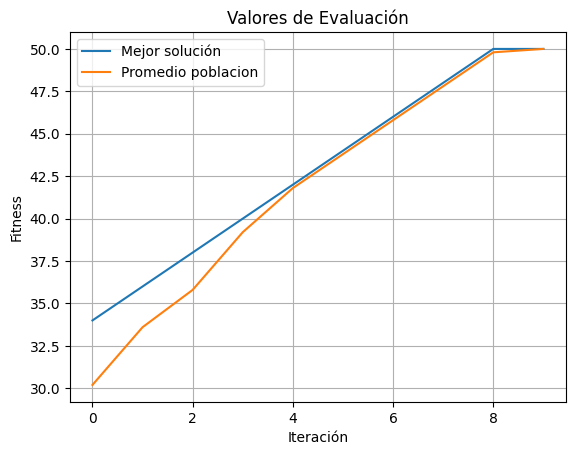

In [319]:
# @title
# Ejercicio 3: ordenar una cadena binaria.
# Objetivo: maximizar la cantidad de bits bien ubicados

# Este es el fitnes que solamente cumple si y sólo si estamos ante una cadena PAR; lo cual no es lo que pide el problema,
# pero lo vimos dentro de clases.
def fitness_visto_en_clase(X):
    mitad = len(X) // 2

    return (
        sum(bit == 0 for bit in X[:mitad])
        + sum(bit == 1 for bit in X[mitad:])
    )

# Como al final supusimos, existen varias formas de encarar la función de fitness; y si el AG está bien programado, técnicamente
# debería llegar todo a lo mismo, la intuición para el desarrollo de esta func de fitness nace:
# Básicamente si vos tenes una codificación [0,0,1,1,0,0] si vos dividis en /2, técnicamente le haces un .split a ese array y sobre eso agarras
# el primero ([0]) entonces obviamente te dará la parte izq que debería estar orednada con todos 0, por lo tanto simplemente lo sumas y si no te da 0
# entonces de esa forma le podes decir al AG mediante la func de fitness que no es por ahí la evolución. Que es una forma necesaria al desarrollar cualquier AG
# es darle la retroalimentación necesaria para que el algoritmo pueda entender y pueda buscar la forma de adaptarse.
# Pero esto tiene un problema, si viene una cadena que no tiene la misma cantidad de 0 que de 1, entonces no sirve de nada, ya que siempre el al splitear el [0]
# te puede dar un valor != 0, así que la solucion es simplemente spliteando en la cantidad contada de 0

cadena_inicial = [random.randint(0, 1) for _ in range(n)]
cant_ceros_objetivo = cadena_inicial.count(0)

# Esto es una mala idea después hay que probar otra formula sobre contar la cantidad por que estamos perdiendo los índices.
def fitness_binario(X):
    frontera = cant_ceros_objetivo

    unos_mal = sum(X[:frontera])       # unos que deberían ser ceros
    ceros_mal = X[frontera:].count(0)  # ceros que deberían ser unos

    return len(X) - (unos_mal + ceros_mal)



# Parámetros
cant_individuos = 10
n = 50
cant_elite = 1

f = fitness_binario
cant_generac = 10

sel = sel_torneo_con_rep
param_sel = 2

xover = xov_uniform_con_conteo
cant_cruzados = round(0.80 * cant_individuos)

mut = mut_swap_dirigido
cant_mutados = cant_individuos

callback = callback_print

# Población inicial
Pop = init_pop_binaria(cant_individuos, cadena_inicial)

# Ejecución
sol, solF, Pop, Fit, traceBest, traceAvg, bestSols = geneticoSimpleBinario(
    Pop=Pop,
    cant_generac=cant_generac,
    sel=sel,
    xover=xover,
    mut=mut,
    cant_cruzados=cant_cruzados,
    cant_mutados=cant_mutados,
    cant_elite=cant_elite,
    param_sel=param_sel,
    f=f,
    callback=callback
)

# ResultadosS
print("Solución", sol, sol.count(0))
print("Cadena inicial", cadena_inicial, cadena_inicial.count(0))
print("Ok?", sum(sol[:cant_ceros_objetivo]) == 0)

print("Fitness obtenido:", solF)

graficarEvolucionFitness(traceBest, traceAvg)

In [165]:
# @title
#def fitness_binario(X):
#    frontera = cant_ceros_objetivo
 #   unos_mal = sum(X[:frontera])       # unos que deberían ser ceros
  #  ceros_mal = X[frontera:].count(0)  # ceros que deberían ser unos

    #return len(X) - (unos_mal + ceros_mal)

cadena = [0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0]

# Okey tengo una cantidad 'frontera' de ceros.
frontera = cadena.count(0)
# Si la cantidad 'frontera' de ceros es X; entonces yo
primer_array = cadena[:frontera]
segundo_array = cadena[frontera:]
print("cadena original:", cadena)
print("primera parte: ", primer_array)
print("segunda parte:", segundo_array)

# Cuento la cantidad de 1 que pertenecen al primer array, que no deberían estar ahí (Por orden)
unos_mal = sum(primer_array)
# Cuento la cantidad de ceros que estén en el segundo array, que deberían estar en el primer array
ceros_mal = segundo_array.count(0)

print("unos_mal", unos_mal)
print("ceros_mal", ceros_mal)
fitness = len(cadena) - (unos_mal + ceros_mal)
print("fitness", fitness)


cadena original: [0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0]
primera parte:  [0, 0, 1, 0, 0, 0, 0, 0, 0]
segunda parte: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0]
unos_mal 1
ceros_mal 1
fitness 18
